# 02 — Degradations gallery

**Goal:** see what a face photo looks like after the kinds of damage it suffers in real life before it reaches a KYC app.

In real onboarding, people send selfies from cheap phones, in bad light, through messaging apps.
A deepfake detector trained only on clean photos may fail on these damaged ones.
The project calls each kind of damage a **degradation** and gives it a **severity** from 1 (a little) to 5 (a lot).

This notebook only **shows pictures**. Nothing is trained, nothing is saved.

**How to use:** run the cells from top to bottom (Shift+Enter). Works on your own computer, in Google Colab and on Kaggle. No GPU needed.
The dataset is optional: without it, the notebook uses a made-up test image.

### Running on Kaggle? One-time setup

In the notebook editor, open the right-hand panel:

- **Settings → Internet → On.** Needed to download the project code from GitHub. Kaggle asks you to verify your phone once.
- **Add Input → Datasets →** search **"140k Real and Fake Faces"** (by xhlulu) → **Add**. These are the images;
  Kaggle attaches them read-only under `/kaggle/input/`, so nothing is downloaded or unzipped.

The code finds everything by itself: `ON_KAGGLE` in Step 1 is `True` when running on Kaggle.
Files you create go to `/kaggle/working/`; they are kept only when you click **Save Version**.

## Step 1 — Find the project and pick one face

**What this does, in plain words:**

1. Loads the Python tools we need.
2. Finds the project folder. On Colab and Kaggle it is not there yet, so it downloads (clones) it from GitHub.
3. Reads `configs/base.yaml` to learn where the images are.
4. Picks one random training face.
   - **On Colab** every notebook runs on its own fresh computer, so the images from notebook 01 are not here.
     The cell then unpacks just a few faces (about 10) from `MyDrive/archive.zip`, the same zip as notebook 01. This takes seconds.
   - **On Kaggle** it uses the dataset you attached with Add Input, so there is nothing to unpack.
   - If there is no dataset and no zip, it makes a simple test image instead, so the notebook still runs.

Cloning into '/kaggle/working/UOT_SCS_3546_041_Deep-Learning'...


Project folder: /kaggle/working/UOT_SCS_3546_041_Deep-Learning
Images folder: /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake
Using this face: real / 00704.jpg


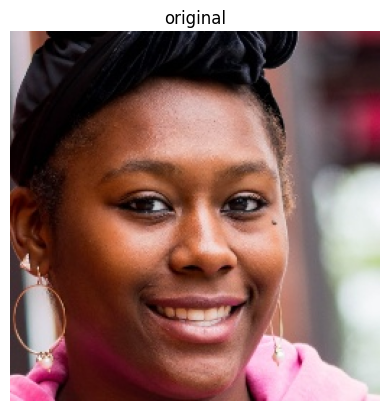

In [1]:
# 1. Tools we need
import random
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Where are we running? Each platform keeps files in a different place.
import os
ON_COLAB = "google.colab" in sys.modules                              # Google Colab
# Kaggle sets the variable KAGGLE_KERNEL_RUN_TYPE. (Checking for a /kaggle folder is not enough:
# newer Colab versions have a /kaggle folder too.)
ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ and not ON_COLAB   # Kaggle notebook

# 2. Find the project folder: look in the current folder and every folder above it.
PROJECT_ROOT = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "deepfake_kyc").is_dir():
        PROJECT_ROOT = folder
        break

# Not found (for example on Colab or Kaggle)? Download the project from GitHub into the current folder.
# (On Kaggle this needs Internet switched on: Settings -> Internet -> On.)
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path.cwd() / "UOT_SCS_3546_041_Deep-Learning"
    if not PROJECT_ROOT.exists():
        subprocess.run(["git", "clone", "https://github.com/msondhi/UOT_SCS_3546_041_Deep-Learning.git",
                        str(PROJECT_ROOT)], check=True)
print("Project folder:", PROJECT_ROOT)

# 3. Read the settings file and load the project's degradation code.
sys.path.insert(0, str(PROJECT_ROOT / "src"))   # lets Python import the project's own code
from deepfake_kyc.config import load_config
from deepfake_kyc.degradations import DEGRADATIONS

cfg = load_config(PROJECT_ROOT / "configs" / "base.yaml")
DATA_ROOT = PROJECT_ROOT / cfg["data"]["root"]     # folder with train/ valid/ test/

# On Kaggle the dataset is attached read-only under /kaggle/input (Add Input -> "140k Real and Fake Faces"),
# so we use it from there instead of data/raw/. Nothing needs to be downloaded or unzipped.
def find_kaggle_dataset():
    """Look inside /kaggle/input for the folder called real-vs-fake that has train/ valid/ test/."""
    for depth in range(1, 5):                                  # look 1, 2, 3, then 4 folders deep
        pattern = "/".join(["*"] * depth) + "/real-vs-fake"    # e.g. "*/*/real-vs-fake"
        for folder in Path("/kaggle/input").glob(pattern):
            if (folder / "train").is_dir():
                return folder
    return None

if ON_KAGGLE and find_kaggle_dataset() is not None:
    DATA_ROOT = find_kaggle_dataset()
print("Images folder:", DATA_ROOT)
TRAIN_DIR = DATA_ROOT / "train"

# 4. Pick one face: a real training photo if we have the dataset, otherwise a simple test image.
train_images = sorted(TRAIN_DIR.glob("*/*.jpg"))   # train/real/*.jpg and train/fake/*.jpg

# On Colab: no images yet? Unpack only a few faces from the dataset zip in Google Drive.
DRIVE_ZIP = "/content/drive/MyDrive/archive.zip"   # same as notebook 01; change if your zip is elsewhere
if not train_images and ON_COLAB:
    import zipfile
    from google.colab import drive
    drive.mount("/content/drive")      # asks you to allow access to your Drive
    if Path(DRIVE_ZIP).exists():
        with zipfile.ZipFile(DRIVE_ZIP) as archive:
            faces = [name for name in archive.namelist() if "/train/" in name and name.endswith(".jpg")]
            few_faces = faces[:5] + faces[-5:]    # a few from the start and the end of the zip
            archive.extractall(PROJECT_ROOT / "data" / "raw", members=few_faces)
        print(f"Unpacked {len(few_faces)} faces from {DRIVE_ZIP}")
        train_images = sorted(TRAIN_DIR.glob("*/*.jpg"))
    else:
        print("Not found in your Drive:", DRIVE_ZIP)
if train_images:
    random.seed(0)                                  # same face every time you run the cell
    face_path = random.choice(train_images)
    face = Image.open(face_path).convert("RGB")
    print("Using this face:", face_path.parent.name, "/", face_path.name)
else:
    # Smooth colour gradient with a white circle: easy to see blur, blocks and noise on it.
    x = np.linspace(0, 255, 256, dtype=np.uint8)
    pixels = np.stack([np.tile(x, (256, 1)), np.tile(x[:, None], (1, 256)), np.full((256, 256), 128, np.uint8)], axis=2)
    yy, xx = np.mgrid[:256, :256]
    pixels[(yy - 128) ** 2 + (xx - 128) ** 2 < 60 ** 2] = 255
    face = Image.fromarray(pixels)
    print("No face photos found, so using a test image instead.")
    print("To see a real face: on Colab put archive.zip in MyDrive; on Kaggle use Add Input -> \"140k Real and Fake Faces\";")
    print("on your computer use notebook 01, Step 2.")

plt.imshow(face)
plt.axis("off")
plt.title("original")
plt.show()

## Step 2 — The five kinds of damage

| Name | What happens in real life |
|---|---|
| `jpeg` | The photo was squeezed to a small file, e.g. sent through WhatsApp |
| `blur` | Out-of-focus or shaky camera |
| `downscale` | A tiny low-resolution photo was stretched back up, so it looks blocky |
| `noise` | Photo taken in bad light, so it looks grainy |
| `screen` | Someone photographed a screen showing the face: stripes (moiré), colour tint, a little blur |

**Try one yourself:** change `name` and `severity` below and run the cell again.

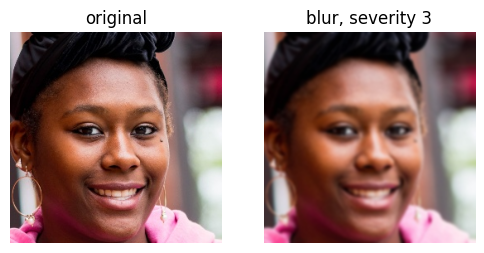

In [2]:
name = "blur"      # try "jpeg", "blur", "downscale", "noise" or "screen"
severity = 3       # 1 = a little damage ... 5 = a lot

damage = DEGRADATIONS[name](severity)   # build the damage step
damaged_face = damage(face)             # apply it to our face

fig, (left, right) = plt.subplots(1, 2, figsize=(6, 3))
left.imshow(face)
left.set_title("original")
right.imshow(damaged_face)
right.set_title(f"{name}, severity {severity}")
left.axis("off")
right.axis("off")
plt.show()

## Step 3 — The full gallery

**What this does:** one row per kind of damage, one column per severity (the first column is the original).

**Why:** later, notebook 03 shows charts like *"accuracy drops at blur severity 4"*. This grid shows you what
*blur severity 4* actually looks like, so you can judge whether that much damage is realistic.
It is also a good figure for the report.

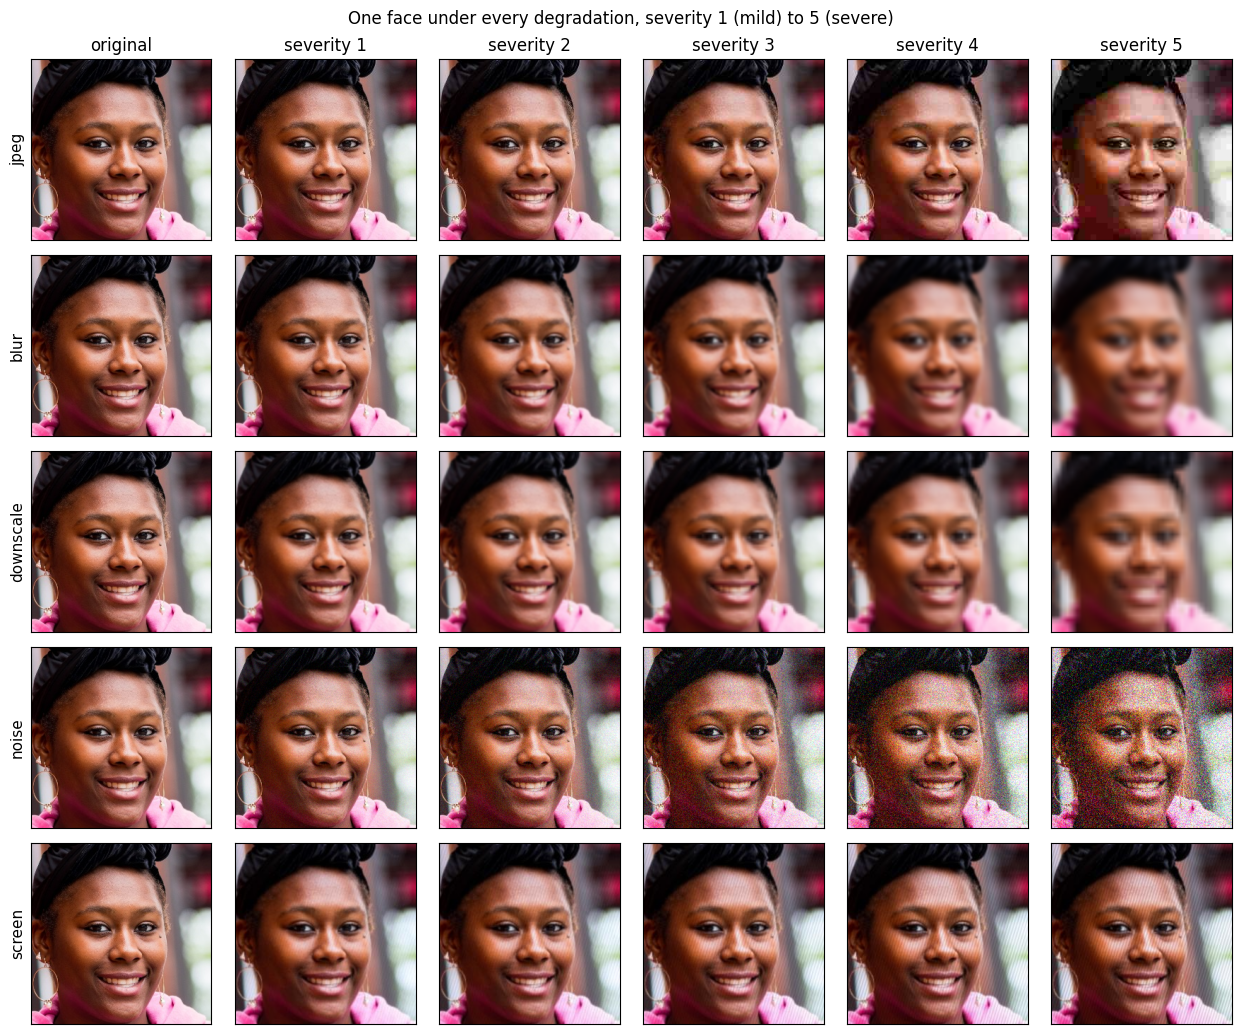

In [3]:
names = list(DEGRADATIONS)     # ['jpeg', 'blur', 'downscale', 'noise', 'screen']
severities = [1, 2, 3, 4, 5]

fig, axes = plt.subplots(len(names), 6, figsize=(12.6, 2.1 * len(names)))
for row, name in enumerate(names):
    # first column: the original face
    axes[row, 0].imshow(face)
    axes[row, 0].set_ylabel(name, fontsize=11)
    # next five columns: severity 1 to 5
    for severity in severities:
        axes[row, severity].imshow(DEGRADATIONS[name](severity)(face))

for col, title in enumerate(["original"] + [f"severity {s}" for s in severities]):
    axes[0, col].set_title(title)
for ax in axes.flat:           # hide the axis numbers on every small picture
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("One face under every degradation, severity 1 (mild) to 5 (severe)")
plt.tight_layout()
plt.show()

## Where this same damage code is used later

The pictures above come from `src/deepfake_kyc/degradations.py`. The project uses that same code in two places:

- **Training (makes the model tougher):** `augment.degradation: true` in `configs/base.yaml` (on for every
  experiment except the `06_effnet_clean` control) randomly damages half of the training images,
  so the model gets used to them.
- **Testing (measures how tough the model is):**
  `python -m deepfake_kyc.evaluate --checkpoint outputs/<experiment>/best.pt --degradation all`
  scores the model at every kind and severity of damage and saves the scores in `outputs/<experiment>/eval_*.csv`.

## Next

[03_results_charts.ipynb](03_results_charts.ipynb) reads those `eval_*.csv` files and charts how accuracy
changes as the damage gets worse.